### Streichholzrätsel – Lösung Schritt für Schritt

*39. Bundeswettbewerb Informatik (2020), 1. Runde, Aufgabe 4*

Will man eine Anordnung von Streichhölzern in eine andere überführen, kann man manchmal Arbeit sparen, indem einige
Streichhölzer einfach liegen bleiben. Z. B. kann die linke untere Anordnung dadurch in die rechte überführt werden, dass drei
Streichhölzer auf neue Positionen gelegt werden.

Ein Streichholzrätsel besteht darin, dass man ausgehend von einer zusammenhängenden Anordnung von Streichhölzern auf einem
Tisch durch das Umlegen einer bestimmten Anzahl von Streichhölzern zu einer anderen zusammenhängenden Anordnung gelangen soll.

Alle Streichhölzer gelten dabei als gerade und gleich lang, und es ist immer egal, wo sich der „Kopf“ eines Streichholzes
befindet. Die Streichhölzer berühren sich nur an ihren Enden und kreuzen sich nicht. Jedes Streichholz liegt auf einer
gedachten Geraden, welche mit einer Tischkante einen Winkel bildet, der ein Vielfaches von 30° ist.

#### Aufgabe 4

Definiere ein geeignetes Format zur Darstellung solcher Streichholzanordnungen im Rechner. Schreibe ein Programm, das zwei in
deinem Format vorliegenden Streichholzanordnungen und eine Anzahl umzulegender Streichhölzer als Eingabe nimmt und berechnet,
ob das Rätsel lösbar ist. Falls das Rätsel lösbar ist, soll ausgegeben werden, welche Streichhölzer wie umgelegt werden müssen.

Wende dein Programm auf die Streichholzrätsel an, die du auf den BWINF-Webseiten findest, und dokumentiere die Ergebnisse.

#### Beispieldaten

Die sechs Rätsel `streichhoelzer0.png` bis `streichhoelzer5.png` sind **Bilder** (links „Vorher“, rechts „Nachher“). Das Eingabeformat
muss man selbst festlegen und die Bilder von Hand übertragen. Wir haben das getan: Die Dateien `streichhoelzer0.txt` bis
`streichhoelzer5.txt` im Ordner `beispieldaten` sind unsere Übertragungen (Format siehe unten). Die Anzahl der umzulegenden
Streichhölzer steht nicht dabei; wir bestimmen sie selbst, und zwar als **kleinstmögliche** Zahl.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Geeignete Darstellung:** Das Format entscheidet, wie schwer die Aufgabe wird. Wenn alle Streichhölzer nur in zwölf Richtungen liegen
  und sich nur an den Enden berühren, kann man **alle Punkte mit ganzen Zahlen** beschreiben und braucht keine Kommazahlen. Dann gibt es keine Rundungsfehler,
  und zwei Streichhölzer sind genau dann gleich, wenn ihre Zahlen gleich sind.
- **Verschieben statt Umlegen denken:** Je mehr Streichhölzer liegen bleiben, desto weniger müssen umgelegt werden. Gesucht ist also die Verschiebung der einen Anordnung, bei der
  **möglichst viele Streichhölzer genau auf Streichhölzern der anderen liegen**. Alle anderen müssen umgelegt werden.
- **Alle Möglichkeiten durchprobieren:** Es gibt unendlich viele Verschiebungen, aber nur wenige sinnvolle. Ein Streichholz, das liegen bleibt, liegt nach der Verschiebung auf einem
  bestimmten Streichholz der anderen Anordnung. Es reicht also, jedes Streichholz der ersten auf jedes der zweiten zu legen.
- **Zählen mit einem Dictionary** (für Neugierige): macht das Verfahren schneller.

**Nützliche Funktionen**
- `set(liste)` und `&` (Schnittmenge): Wie viele Streichhölzer liegen in beiden Anordnungen? `len(set(a) & set(b))`
- `dict.get(schluessel, 0)` zum Zählen.
- `matplotlib` (`plt.plot`) zum Zeichnen der Lösung.

## Die Idee

**Verschiebung.** Wir legen die Anordnung „Vorher“ gedanklich auf den Tisch und verschieben sie, bis möglichst viele ihrer Streichhölzer genau auf Streichhölzern von „Nachher“ liegen.
Die Streichhölzer, die dabei **nicht** auf einem Streichholz von „Nachher“ liegen, nimmt man weg. Mit genau so vielen Streichhölzern baut man die fehlenden Stellen von „Nachher“.
Haben beide Anordnungen `N` Streichhölzer und liegen `c` davon übereinander, müssen `N − c` Streichhölzer umgelegt werden.

**Kleinstes K.** Ob das Rätsel mit `k` Zügen lösbar ist, hängt also nur davon ab, ob `N − c ≤ k` für das **größte** `c` gilt. Hier kommt es auf die Verschiebung an, nicht auf die Reihenfolge der Züge.
(Bei den Rätseln der Aufgabe wird immer ein Streichholz auf einmal umgelegt und es darf dazwischen irgendwie aussehen.)

**Verdrehen** wollen wir die Anordnung nicht: Wer ein Rätsel lösen will, dessen Ergebnis insgesamt gedreht ist, sucht ein anderes Rätsel. Wie man das trotzdem
in das Verfahren einbaut, zeigen wir am Ende („Für Neugierige“).

**Und die Zahlen?** Jetzt fehlt noch eine Darstellung, mit der man Streichhölzer exakt verschieben und vergleichen kann.

## Schritt 1: Punkte und Richtungen ohne Kommazahlen

Wir legen die Länge eines Streichholzes auf **2 Einheiten** fest. Ein Streichholz in Richtung 0° ist dann der Vektor $(2, 0)$, eines in Richtung 90° ist $(0, 2)$.
Bei 30° ist es $(2\cos 30°, 2\sin 30°) = (\sqrt 3, 1)$, bei 60° ist es $(1, \sqrt 3)$. Es kommt also die Zahl $\sqrt 3$ ins Spiel. Sie ist irrational und lässt sich nie genau als Kommazahl schreiben.

Der Trick: **Wir rechnen gar nicht mit $\sqrt 3$, sondern merken uns, wie oft sie vorkommt.** Jede Koordinate hat die Form „ganze Zahl plus ganze Zahl mal $\sqrt 3$“. Einen Punkt schreiben wir deshalb als
**vier ganze Zahlen** `(x, y, z, w)` für den Punkt $(x + z\sqrt 3,\; y + w\sqrt 3)$. Zum Beispiel ist `(0, 1, 1, 0)` der Punkt $(\sqrt 3, 1)$.
Addieren geht Zahl für Zahl, und zwei Punkte sind genau dann gleich, wenn alle vier Zahlen gleich sind. (Das stimmt, weil $\sqrt 3$ keine Bruchzahl ist: Es kann nicht $x + z\sqrt 3 = x' + z'\sqrt 3$ gelten, wenn $z \ne z'$.)

**Die zwölf Richtungen.** Drehen wir einen Vektor um 30° (gegen den Uhrzeigersinn), erhalten wir aus $(x + z\sqrt 3,\; y + w\sqrt 3)$ den Vektor
$\tfrac12\bigl((3z - y) + (x - w)\sqrt 3,\; (x + 3w) + (y + z)\sqrt 3\bigr)$. (Das ist die Multiplikation mit der Drehmatrix, mit $\sqrt 3 \cdot \sqrt 3 = 3$ ausgerechnet.)
In Zahlen: `(x, y, z, w)` wird zu `((3z − y) / 2, (x + 3w) / 2, (x − w) / 2, (y + z) / 2)`. Bei unseren Vektoren sind die Ergebnisse immer ganze Zahlen.
Wir starten bei `(2, 0, 0, 0)` und drehen elfmal weiter.

In [ ]:
from math import sqrt


def drehe30(p):
    x, y, z, w = p
    return ((3 * z - y) // 2, (x + 3 * w) // 2, (x - w) // 2, (y + z) // 2)


RICHTUNG = [(2, 0, 0, 0)]            # RICHTUNG[r] ist der Vektor eines Streichholzes mit Winkel 30 * r Grad
for r in range(11):
    RICHTUNG.append(drehe30(RICHTUNG[-1]))

for r in range(12):
    print(f'{30 * r:3d} Grad:', RICHTUNG[r])
print('Nach zwölf Drehungen wieder am Anfang:', drehe30(RICHTUNG[11]) == RICHTUNG[0])

  0 Grad: (2, 0, 0, 0)
 30 Grad: (0, 1, 1, 0)
 60 Grad: (1, 0, 0, 1)
 90 Grad: (0, 2, 0, 0)
120 Grad: (-1, 0, 0, 1)
150 Grad: (0, 1, -1, 0)
180 Grad: (-2, 0, 0, 0)
210 Grad: (0, -1, -1, 0)
240 Grad: (-1, 0, 0, -1)
270 Grad: (0, -2, 0, 0)
300 Grad: (1, 0, 0, -1)
330 Grad: (0, -1, 1, 0)
Nach zwölf Drehungen wieder am Anfang: True


Man sieht: Bei 0°, 90°, 180° und 270° kommt $\sqrt 3$ nicht vor, bei 30°, 150°, 210° und 330° nur in der ersten Koordinate, bei 60°, 120°, 240° und 300° nur in der zweiten.
Der Vektor für 180° ist das Negative des Vektors für 0° und so weiter: `RICHTUNG[r + 6]` ist `RICHTUNG[r]` mit umgekehrtem Vorzeichen.

Damit können wir Punkte addieren, und wir können sie zum Zeichnen in ganz normale Koordinaten umrechnen (hier in Streichholzlängen, also geteilt durch 2).

In [ ]:
def plus(p, q):
    return (p[0] + q[0], p[1] + q[1], p[2] + q[2], p[3] + q[3])


def ort(p):
    """Gewöhnliche Koordinaten (Kommazahlen, nur zum Zeichnen und Anzeigen), Einheit: eine Streichholzlänge."""
    x, y, z, w = p
    return ((x + z * sqrt(3)) / 2, (y + w * sqrt(3)) / 2)


p = plus(RICHTUNG[1], RICHTUNG[3])        # erst 30 Grad, dann 90 Grad: zwei Streichhölzer hintereinander
print(p, ort(p))

(0, 3, 1, 0) (0.8660254037844386, 1.5)


## Schritt 2: Ein Streichholz als fünf Zahlen

Ein Streichholz hat zwei Enden. Welches der „Kopf“ ist, ist egal, und es ist auch egal, in welcher Richtung wir es aufschreiben. Damit jedes Streichholz **nur auf eine Art** aufgeschrieben wird (sonst
würden sich gleiche Streichhölzer nicht als gleich erkennen lassen), legen wir fest:
Wir schreiben es als `(x, y, z, w, r)`: Dabei ist `(x, y, z, w)` der **Anfangspunkt** und `r` eine Zahl von 0 bis 5 für die Richtung (0°, 30°, ..., 150°). Das andere Ende ist `Anfangspunkt + RICHTUNG[r]`.
Liegt ein Streichholz in einer Richtung von 180° bis 330°, vertauschen wir die Enden, dann liegt es in der Richtung `r − 6`.

`streichholz(punkt, r)` erzeugt diese Standardform aus einem Punkt und einer beliebigen Richtung `r` aus 0 bis 11, und `ende(s)` gibt das zweite Ende zurück.

In [ ]:
def streichholz(punkt, r):
    """Streichholz vom Punkt aus in Richtung 30 * r Grad, in Standardform (x, y, z, w, r) mit 0 <= r < 6."""
    if r < 6:
        return punkt + (r,)
    anfang = plus(punkt, RICHTUNG[r])           # die Enden vertauschen
    return anfang + (r - 6,)


def ende(s):
    return plus(s[:4], RICHTUNG[s[4]])


a = streichholz((0, 0, 0, 0), 2)               # von (0, 0) nach oben rechts (60 Grad)
b = streichholz(ende(a), 8)                    # zurück in der Richtung 240 Grad
print(a, b, a == b)

(0, 0, 0, 0, 2) (0, 0, 0, 0, 2) True


Das zweite Streichholz `b` liegt genau auf `a`, nur andersherum gedacht: Beide haben dieselben fünf Zahlen.

## Schritt 3: Das Eingabeformat und das Einlesen

Die Bilder muss man von Hand übertragen. Dabei will man nicht Koordinaten mit $\sqrt 3$ ausrechnen. Unser Format beschreibt deshalb **Wege**: Man läuft von einem Anfangspunkt aus
Streichholz für Streichholz in einer Richtung (Winkel in Grad, 0 = nach rechts, 90 = nach oben). Jede Zeile hat die Form

```
Anfahrt | Winkel Winkel Winkel ...
```

Links vom Strich steht, wie man vom Nullpunkt **zum Anfang** des Wegs kommt (ebenfalls als Folge von Winkeln, dabei werden keine Streichhölzer gelegt, es ist nur ein Hilfsweg). Rechts vom Strich liegt
bei jedem Winkel ein Streichholz, an das Ende des vorigen angesetzt. Ein Quadrat mit Seitenlänge 1 sieht so aus: `| 0 90 180 270` (rechts, hoch, links, runter). Ein Haus mit Dach: das Quadrat und dazu `90 | 60 300`
(Anfahrt zur linken oberen Ecke, dann zwei Streichhölzer für das Dach). Eine Datei enthält die Zeilen von „vorher“ und die von „nachher“:

```
vorher
| 0 90 180 270
nachher
90 | 0 90 180 270
```
Zeilen, die mit `#` beginnen, sind Kommentare. So sieht `streichhoelzer0.txt` aus (unsere Übertragung von `streichhoelzer0.png`):

In [ ]:
with open('beispieldaten/streichhoelzer0.txt', encoding='utf-8') as f:
    print(f.read())

# Streichholzrätsel, von Hand aus streichhoelzerN.png übertragen. Format siehe Lösungsnotebook:
# je Zeile "Anfahrt | Streichhölzer", Winkel in Grad (0 = nach rechts, 90 = nach oben), eine Streichholzlänge je Schritt.
vorher
| 0 90 180 270
90 | 60 300
90 60 | 90
nachher
| 90 60 300 270 120
| 60
60 | 90



`laufe(anfahrt, winkel)` läuft einen Weg und gibt die gelegten Streichhölzer in Standardform zurück. `lies_raetsel(dateiname)` liest die Datei und gibt die beiden Anordnungen als Listen zurück.
Wir prüfen dabei, dass kein Streichholz doppelt vorkommt, denn zwei Streichhölzer können nicht auf demselben Platz liegen.

In [ ]:
def laufe(anfahrt, winkel):
    punkt = (0, 0, 0, 0)
    for w in anfahrt:                                  # Hilfsweg, es wird nichts gelegt
        punkt = plus(punkt, RICHTUNG[w // 30])
    hoelzer = []
    for w in winkel:
        r = w // 30
        hoelzer.append(streichholz(punkt, r))
        punkt = plus(punkt, RICHTUNG[r])
    return hoelzer


def lies_raetsel(dateiname):
    figuren = {'vorher': [], 'nachher': []}
    aktuell = None
    with open(dateiname, encoding='utf-8') as f:
        for zeile in f:
            zeile = zeile.strip()
            if zeile == '' or zeile.startswith('#'):
                continue
            if zeile in figuren:
                aktuell = zeile
                continue
            links, rechts = zeile.split('|')
            anfahrt = [int(w) for w in links.split()]
            winkel = [int(w) for w in rechts.split()]
            figuren[aktuell] += laufe(anfahrt, winkel)
    for name in figuren:
        assert len(set(figuren[name])) == len(figuren[name]), 'Streichholz doppelt: ' + name
    return figuren['vorher'], figuren['nachher']


vorher, nachher = lies_raetsel('beispieldaten/streichhoelzer0.txt')
print(len(vorher), len(nachher))
print(vorher[:3])

7 7
[(0, 0, 0, 0, 0), (2, 0, 0, 0, 3), (0, 2, 0, 0, 0)]


## Schritt 4: Verschieben und Überdeckung zählen

Eine Verschiebung ist ein Punkt `t = (tx, ty, tz, tw)`, der auf jeden Anfangspunkt addiert wird. Die Richtung ändert sich nicht.
`ueberdeckung(a, b, t)` zählt, wie viele Streichhölzer von `a` nach der Verschiebung genau auf einem Streichholz von `b` liegen. Dafür machen wir aus `b` eine **Menge**: Ob ein Element in einer Menge liegt, prüft Python sehr schnell.

In [ ]:
def verschiebe(figur, t):
    return [plus(s[:4], t) + (s[4],) for s in figur]


def ueberdeckung(a, b, t):
    return len(set(verschiebe(a, t)) & set(b))


print(ueberdeckung(vorher, nachher, (0, 0, 0, 0)))

4


Ohne Verschiebung liegen schon vier Streichhölzer übereinander (in unserer Übertragung liegen die Quadrate beider Anordnungen am selben Platz, deshalb ist die Verschiebung 0 schon gut). Ob es mit einer anderen Verschiebung mehr werden, wissen wir noch nicht.
Welche Verschiebungen probieren wir? Wenn ein Streichholz `sa` aus `a` auf ein Streichholz `sb` aus `b` zu liegen kommt, muss die Richtung gleich sein, und die Verschiebung ist dann der Unterschied der Anfangspunkte.
Jede Verschiebung, bei der überhaupt etwas übereinander liegt, entsteht auf diese Weise. Wir probieren also alle Paare `(sa, sb)` mit gleicher Richtung und merken uns die beste Verschiebung.

In [ ]:
def beste_verschiebung(a, b):
    """Gibt (Überdeckung, Verschiebung) mit der größten Überdeckung zurück."""
    beste = (0, (0, 0, 0, 0))
    for sa in a:
        for sb in b:
            if sa[4] == sb[4]:
                t = (sb[0] - sa[0], sb[1] - sa[1], sb[2] - sa[2], sb[3] - sa[3])
                c = ueberdeckung(a, b, t)
                if c > beste[0]:
                    beste = (c, t)
    return beste


c, t = beste_verschiebung(vorher, nachher)
print('Es können', c, 'von', len(vorher), 'Streichhölzern liegen bleiben, Verschiebung', t)
print('Zu bewegen:', len(vorher) - c)

Es können 4 von 7 Streichhölzern liegen bleiben, Verschiebung (0, 0, 0, 0)
Zu bewegen: 3


Das Haus lässt sich also mit **drei** Streichhölzern in die Nachher-Anordnung verwandeln. Das passt zu dem Beispiel im Aufgabentext.

## Schritt 5: Welche Streichhölzer werden wie umgelegt?

Nach der Verschiebung liegen manche Streichhölzer von „Vorher“ auf Streichhölzern von „Nachher“. Die anderen Streichhölzer von „Vorher“ werden **weggenommen**, die Plätze in „Nachher“, auf denen noch keines liegt, werden **belegt**.
Beides sind gleich viele (wenn beide Anordnungen gleich viele Streichhölzer haben). Wir ordnen sie in der Reihenfolge der Liste einander zu. Jedes weggenommene Streichholz wird auf den zugeordneten freien Platz gelegt.

Zum Ausgeben rechnen wir die Punkte mit `ort` zurück in gewöhnliche Koordinaten (in Streichholzlängen, die Nachher-Anordnung bestimmt das Koordinatensystem, der Nullpunkt liegt am Anfang des ersten Wegs der Datei).
`loese(a, b, k)` fasst alles zusammen: Sie gibt `None` zurück, wenn das Rätsel mit `k` Streichhölzern nicht lösbar ist, sonst die Verschiebung, die wegzunehmenden und die zu belegenden Streichhölzer.

In [ ]:
def loese(a, b, k):
    """Rätsel lösbar, wenn mit höchstens k Streichhölzern ein Zug gelingt? Ergebnis: None oder (t, weg, hin)."""
    if len(a) != len(b):
        return None                                  # mit Umlegen ändert sich die Anzahl nicht
    c, t = beste_verschiebung(a, b)
    if len(a) - c > k:
        return None
    a_neu = verschiebe(a, t)
    weg = [s for s in a_neu if s not in set(b)]     # liegen auf keinem Streichholz von b
    hin = [s for s in b if s not in set(a_neu)]     # hier fehlt noch ein Streichholz
    return t, weg, hin


def text(s):
    (x1, y1), (x2, y2) = ort(s[:4]), ort(ende(s))
    return f'({x1:5.2f} | {y1:5.2f}) bis ({x2:5.2f} | {y2:5.2f})'


erg = loese(vorher, nachher, 3)
t, weg, hin = erg
for sw, sh in zip(weg, hin):
    print('Nimm das Streichholz', text(sw), '\n   und lege es auf', text(sh))
print('Mit 2 Streichhölzern lösbar?', loese(vorher, nachher, 2) is not None)

Nimm das Streichholz ( 0.00 |  0.00) bis ( 1.00 |  0.00) 
   und lege es auf ( 1.00 |  0.00) bis ( 0.50 |  0.87)
Nimm das Streichholz ( 0.00 |  1.00) bis ( 1.00 |  1.00) 
   und lege es auf ( 0.00 |  0.00) bis ( 0.50 |  0.87)
Nimm das Streichholz ( 0.50 |  1.87) bis ( 0.50 |  2.87) 
   und lege es auf ( 0.50 |  0.87) bis ( 0.50 |  1.87)
Mit 2 Streichhölzern lösbar? False


## Schritt 6: Das Ergebnis zeichnen

Eine Liste von Koordinaten ist schwer zu lesen. Wir zeichnen deshalb beide Anordnungen: **schwarz** sind die Streichhölzer, die liegen bleiben, **rot** die, die weggenommen werden, und **grün** die, die neu hinzukommen
(Vorbild: die Bilder der Lösungshinweise). Links ist die Anordnung „Vorher“, nach der besten Verschiebung gezeichnet, rechts „Nachher“.

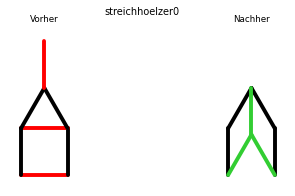

In [ ]:
import matplotlib.pyplot as plt


def zeichne_figur(ax, figur, bleibt, farbe):
    for s in figur:
        (x1, y1), (x2, y2) = ort(s[:4]), ort(ende(s))
        ax.plot([x1, x2], [y1, y2], color='black' if s in bleibt else farbe, linewidth=4, solid_capstyle='round')
    ax.set_aspect('equal')
    ax.axis('off')


def zeichne(titel, a, b, t):
    a_neu = verschiebe(a, t)
    bleibt = set(a_neu) & set(b)
    punkte = [ort(s[:4]) for s in a_neu + b] + [ort(ende(s)) for s in a_neu + b]
    xs, ys = [p[0] for p in punkte], [p[1] for p in punkte]
    fig, achsen = plt.subplots(1, 2, figsize=(7, 3))
    for ax, figur, farbe, name in ((achsen[0], a_neu, 'red', 'Vorher'), (achsen[1], b, 'limegreen', 'Nachher')):
        zeichne_figur(ax, figur, bleibt, farbe)
        ax.set_xlim(min(xs) - 0.3, max(xs) + 0.3)
        ax.set_ylim(min(ys) - 0.3, max(ys) + 0.3)
        ax.set_title(name, fontsize=9)
    fig.suptitle(titel, fontsize=10)
    plt.show()


zeichne('streichhoelzer0', vorher, nachher, t)

Das Haus: Von „Vorher“ bleiben die beiden senkrechten Seiten des Quadrats und die beiden Dachhölzer liegen (schwarz), das sind vier Streichhölzer. Rot sind die oberste Senkrechte und die beiden waagrechten Quadratseiten. Sie kommen auf die grünen Plätze: eine Senkrechte in die Mitte und zwei schräg unten.
Genau so wollen wir das gleich für alle sechs Rätsel sehen.

## Schritt 7: Alle Beispiele

Für jedes Rätsel suchen wir mit `beste_verschiebung` die kleinste Zahl `k` umzulegender Streichhölzer. Dazu rechnen wir `N − c` aus und prüfen mit `loese`, dass es mit `k` geht und mit `k − 1` nicht.
Zuerst eine Übersicht:

In [ ]:
raetsel = {}
for nr in range(6):
    a, b = lies_raetsel(f'beispieldaten/streichhoelzer{nr}.txt')
    c, t = beste_verschiebung(a, b)
    k = len(a) - c
    assert loese(a, b, k) is not None and (k == 0 or loese(a, b, k - 1) is None)
    raetsel[nr] = (a, b, k, t)
    print(f'streichhoelzer{nr}: {len(a)} Streichhölzer (Vorher), {len(b)} (Nachher), höchstens {c} bleiben liegen, also k = {k}')

streichhoelzer0: 7 Streichhölzer (Vorher), 7 (Nachher), höchstens 4 bleiben liegen, also k = 3
streichhoelzer1: 9 Streichhölzer (Vorher), 9 (Nachher), höchstens 5 bleiben liegen, also k = 4
streichhoelzer2: 14 Streichhölzer (Vorher), 14 (Nachher), höchstens 11 bleiben liegen, also k = 3
streichhoelzer3: 16 Streichhölzer (Vorher), 16 (Nachher), höchstens 8 bleiben liegen, also k = 8
streichhoelzer4: 16 Streichhölzer (Vorher), 16 (Nachher), höchstens 14 bleiben liegen, also k = 2
streichhoelzer5: 9 Streichhölzer (Vorher), 9 (Nachher), höchstens 5 bleiben liegen, also k = 4


Jetzt die Lösungen: erst die Texte, dann die Bilder.

In [ ]:
for nr in range(6):
    a, b, k, t = raetsel[nr]
    t, weg, hin = loese(a, b, k)
    print(f'streichhoelzer{nr}: {k} Streichhölzer umlegen')
    for sw, sh in zip(weg, hin):
        print('   von', text(sw), ' nach', text(sh))

streichhoelzer0: 3 Streichhölzer umlegen
   von ( 0.00 |  0.00) bis ( 1.00 |  0.00)  nach ( 1.00 |  0.00) bis ( 0.50 |  0.87)
   von ( 0.00 |  1.00) bis ( 1.00 |  1.00)  nach ( 0.00 |  0.00) bis ( 0.50 |  0.87)
   von ( 0.50 |  1.87) bis ( 0.50 |  2.87)  nach ( 0.50 |  0.87) bis ( 0.50 |  1.87)
streichhoelzer1: 4 Streichhölzer umlegen
   von (-0.87 |  0.50) bis (-0.87 |  1.50)  nach ( 0.00 | -1.00) bis (-0.87 | -0.50)
   von ( 0.00 |  1.00) bis (-0.87 |  1.50)  nach ( 0.00 | -1.00) bis ( 0.87 | -0.50)
   von ( 0.00 |  0.00) bis (-0.87 |  0.50)  nach ( 0.87 | -0.50) bis ( 0.87 |  0.50)
   von ( 0.00 |  0.00) bis ( 0.87 |  0.50)  nach ( 0.87 | -0.50) bis ( 0.00 |  0.00)
streichhoelzer2: 3 Streichhölzer umlegen
   von (-0.87 |  0.50) bis ( 0.00 |  1.00)  nach ( 0.00 |  1.00) bis (-0.87 |  1.50)
   von ( 2.87 |  0.50) bis ( 2.00 |  1.00)  nach ( 1.13 |  0.50) bis ( 2.00 |  1.00)
   von ( 2.00 |  0.00) bis ( 2.87 |  0.50)  nach ( 2.00 |  0.00) bis ( 1.13 |  0.50)
streichhoelzer3: 8 Streichh

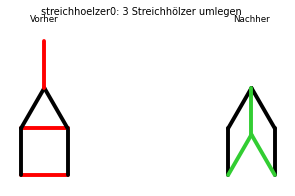

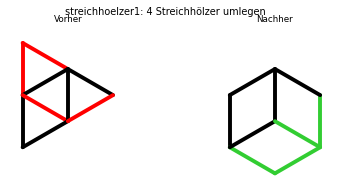

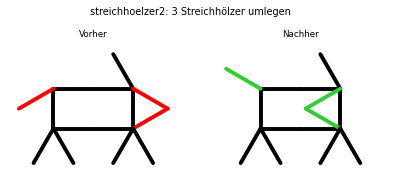

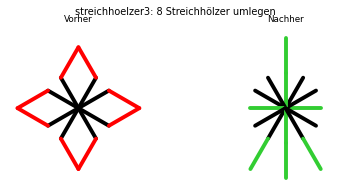

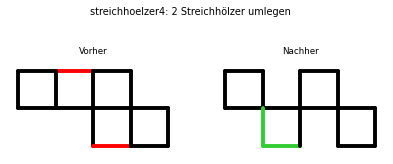

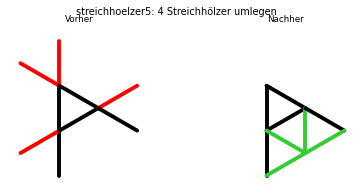

In [ ]:
for nr in range(6):
    a, b, k, t = raetsel[nr]
    zeichne(f'streichhoelzer{nr}: {k} Streichhölzer umlegen', a, b, t)

Die kleinsten Zahlen umzulegender Streichhölzer für die sechs Rätsel sind also 3, 4, 3, 8, 2 und 4. Zum Abgleich haben wir nur das Beispiel aus der Aufgabenstellung (Haus, drei Streichhölzer, stimmt)
und die Bilder der Lösungshinweise, zu denen keine Zahlen im Text stehen. Auffällig ist `streichhoelzer3`: Von den 16 Streichhölzern bleiben nur die 8 liegen, die vom Mittelpunkt wegzeigen,
aus der Blüte wird ein Stern. Bei `streichhoelzer1` und `streichhoelzer5` kommt dieselbe Figur aus Dreiecken (die „Pfeilspitze“) einmal als Anordnung und einmal als Ziel vor, beide Rätsel brauchen vier Züge.

*Was wir nicht prüfen:* dass die Anordnungen zusammenhängend sind (sie sind es in den Rätseln) und dass die Streichhölzer sich nicht kreuzen (das tun sie nach den Regeln nicht). Das Verfahren findet das **kleinste** `k`.
Wer mit mehr Zügen lösen darf, hat es leichter.

## Für Neugierige: schneller zählen

Unser `beste_verschiebung` ruft für jedes Paar von Streichhölzern mit gleicher Richtung `ueberdeckung` auf, und das vergleicht wieder alle `N` Streichhölzer. Das sind ungefähr `N³` Schritte
(so steht es auch im Lösungshinweis). Es geht mit `N²`: Jedes Paar `(sa, sb)` mit gleicher Richtung „stimmt“ für genau eine Verschiebung, nämlich den Unterschied der Anfangspunkte.
Wir zählen in einem **Dictionary** mit, wie oft jede Verschiebung vorkommt. Die Verschiebung, die am häufigsten vorkommt, lässt die meisten Streichhölzer übereinander liegen. Jedes Streichholz von `a` wird dabei höchstens
einmal gezählt, weil es in `b` nur ein Streichholz mit dieser Richtung und diesem Anfangspunkt gibt.

In [ ]:
def beste_verschiebung_schnell(a, b):
    zaehler = {}
    for sa in a:
        for sb in b:
            if sa[4] == sb[4]:
                t = (sb[0] - sa[0], sb[1] - sa[1], sb[2] - sa[2], sb[3] - sa[3])
                zaehler[t] = zaehler.get(t, 0) + 1
    beste = (0, (0, 0, 0, 0))
    for t in zaehler:
        if zaehler[t] > beste[0]:
            beste = (zaehler[t], t)
    return beste


for nr in range(6):
    a, b, k, t = raetsel[nr]
    paare = sum(1 for sa in a for sb in b if sa[4] == sb[4])
    c_schnell, t_schnell = beste_verschiebung_schnell(a, b)
    print(f'streichhoelzer{nr}: {paare} Paare mit gleicher Richtung; einfach: {paare * len(a)} Vergleiche, mit Dictionary: {paare}; '
          f'dieselbe Überdeckung: {c_schnell == len(a) - k}')

streichhoelzer0: 13 Paare mit gleicher Richtung; einfach: 91 Vergleiche, mit Dictionary: 13; dieselbe Überdeckung: True
streichhoelzer1: 27 Paare mit gleicher Richtung; einfach: 243 Vergleiche, mit Dictionary: 27; dieselbe Überdeckung: True
streichhoelzer2: 37 Paare mit gleicher Richtung; einfach: 518 Vergleiche, mit Dictionary: 37; dieselbe Überdeckung: True
streichhoelzer3: 40 Paare mit gleicher Richtung; einfach: 640 Vergleiche, mit Dictionary: 40; dieselbe Überdeckung: True
streichhoelzer4: 128 Paare mit gleicher Richtung; einfach: 2048 Vergleiche, mit Dictionary: 128; dieselbe Überdeckung: True
streichhoelzer5: 27 Paare mit gleicher Richtung; einfach: 243 Vergleiche, mit Dictionary: 27; dieselbe Überdeckung: True


Bei diesen kleinen Rätseln ist der Unterschied nicht spürbar, bei Anordnungen mit Hunderten von Streichhölzern schon.

## Für Neugierige: wenn „Nachher“ gedreht ist

Der Lösungshinweis erlaubt, dass Rätsel, bei denen das Ziel **insgesamt gedreht** liegt, nicht erkannt werden. Wir können sie aber leicht auch lösen: Wir drehen „Nachher“ um 0°, 30°, ..., 330° um den Nullpunkt, suchen jedes Mal die beste
Verschiebung und nehmen die beste Drehung. Das Drehen rechnen wir mit `drehe30` aus Schritt 1: Wir drehen beide Enden jedes Streichholzes und bilden daraus wieder ein Streichholz in Standardform.
Aus dem Unterschied der Enden bekommen wir die Richtung zurück, indem wir im Dictionary `RICHTUNG_NR` nachschlagen.

In [ ]:
RICHTUNG_NR = {v: r for r, v in enumerate(RICHTUNG)}


def drehe_punkt(p, n):
    for _ in range(n):
        p = drehe30(p)
    return p


def drehe_figur(figur, n):
    """Dreht die Figur um n mal 30 Grad um den Nullpunkt."""
    neu = []
    for s in figur:
        p, q = drehe_punkt(s[:4], n), drehe_punkt(ende(s), n)
        diff = (q[0] - p[0], q[1] - p[1], q[2] - p[2], q[3] - p[3])
        neu.append(streichholz(p, RICHTUNG_NR[diff]))
    return neu


def beste_mit_drehung(a, b):
    """(Überdeckung, Drehung in 30-Grad-Schritten, Verschiebung): b wird gedreht, a nur verschoben."""
    beste = (-1, 0, (0, 0, 0, 0))
    for n in range(12):
        c, t = beste_verschiebung_schnell(a, drehe_figur(b, n))
        if c > beste[0]:
            beste = (c, n, t)
    return beste


# Beispiel: der Hund aus streichhoelzer2, aber „Nachher“ um 60 Grad gedreht
a, b, k, t = raetsel[2]
b_gedreht = drehe_figur(b, 2)
c0, t0 = beste_verschiebung_schnell(a, b_gedreht)
print('Ohne Drehung:', len(a) - c0, 'Streichhölzer umlegen')
c1, n1, t1 = beste_mit_drehung(a, b_gedreht)
print('Mit Drehung:', len(a) - c1, 'Streichhölzer umlegen, „Nachher“ wird um', 30 * n1, 'Grad zurückgedreht')

Ohne Drehung: 10 Streichhölzer umlegen
Mit Drehung: 3 Streichhölzer umlegen, „Nachher“ wird um 300 Grad zurückgedreht


Ohne Drehung brauchen wir für den gedrehten Hund 10 statt 3 Züge, er lässt sich kaum noch mit dem ursprünglichen Hund zur Deckung bringen. Mit der Suche über alle zwölf Drehungen finden wir wieder die drei Streichhölzer von vorher. Eine
Drehung um 300° (10 Schritte zu 30°) macht die Drehung um 60° rückgängig.
Spiegelungen haben wir nicht eingebaut.

## Zum Schluss: Verschiebung mit MiniZinc suchen

Die Suche nach der besten Verschiebung lässt sich auch dem **Solver** überlassen. Die Verschiebung `t` besteht aus vier ganzen Zahlen, also **vier Variablen**. Für jedes Streichholz `i` von „Vorher“ soll gelten: Es gibt ein Streichholz `j` von „Nachher“ mit
derselben Richtung und demselben Anfangspunkt nach der Verschiebung. Das schreibt man mit `exists`. Die Anzahl `c` der erfüllten Streichhölzer soll **maximal** werden (`solve maximize c`).
Neu gegenüber den Arbeitsblättern sind nur:

- **`var -R..R: t`**: Variablen mit einem Wertebereich (hier ganze Zahlen von −R bis R), die der Solver selbst wählt. Ein Feld solcher Variablen ist `array[1..4] of var -R..R: t`.
- **`exists(j in 1..n)(Bedingung)`**: wahr, wenn die Bedingung für mindestens ein `j` gilt (so wie `forall` für alle).
- **`bool2int`**: macht aus wahr/falsch die Zahl 1/0, damit man mit `sum` zählen kann.
- **`solve maximize c;`** statt `solve satisfy`: Der Solver sucht den größten Wert von `c`.

Die Streichhölzer übergeben wir als Tabellen: je eine Zeile `(x, y, z, w)` für den Anfangspunkt und eine Liste der Richtungen. Diese Datei erzeugt eine Python-Zelle aus unseren Daten.

In [ ]:
def als_dzn(a, b):
    r = max(abs(v) for s in a + b for v in s[:4]) * 2 + 2            # größer als jede sinnvolle Verschiebung
    def tabelle(figur):
        return 'array2d(1..%d, 1..4, %s)' % (len(figur), [v for s in figur for v in s[:4]])
    return (f'n = {len(a)};\nR = {r};\na = {tabelle(a)};\nar = {[s[4] for s in a]};\n'
            f'b = {tabelle(b)};\nbr = {[s[4] for s in b]};\n')


print(als_dzn(*raetsel[0][:2]))

n = 7;
R = 6;
a = array2d(1..7, 1..4, [0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 2, 2, 0, 0, 1, 2, 0, 1]);
ar = [0, 3, 0, 3, 2, 4, 3];
b = array2d(1..7, 1..4, [0, 0, 0, 0, 0, 2, 0, 0, 2, 2, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1]);
br = [3, 2, 4, 3, 4, 2, 3];



#### Das Modell

```minizinc
int: n;                                   % Anzahl der Streichhölzer
int: R;                                   % Wertebereich der Verschiebung
array[1..n, 1..4] of int: a;              % Anfangspunkte „Vorher“, je Zeile (x, y, z, w)
array[1..n] of int: ar;                   % Richtungen „Vorher“ (0 bis 5)
array[1..n, 1..4] of int: b;              % dasselbe für „Nachher“
array[1..n] of int: br;

array[1..4] of var -R..R: t;              % die gesuchte Verschiebung

% c: Anzahl der Streichhölzer von a, die nach der Verschiebung genau auf einem Streichholz von b liegen
var 0..n: c = sum(i in 1..n)(bool2int(exists(j in 1..n)(
    ar[i] = br[j] /\ forall(k in 1..4)(a[i, k] + t[k] = b[j, k]))));

solve maximize c;

output ["c = \(c)\n", "t = \(t)\n"];
```

Mit den Daten von `streichhoelzer0` (siehe oben) gibt der Solver (Gecode):

**Ausgabe:**

```
c = 4
t = [0, 0, 0, 0]
----------
==========
```

Das sind dieselben 4 übereinanderliegenden Streichhölzer wie bei uns, bei der Verschiebung 0. Die Ergebnisse für alle Rätsel (die Verschiebung `t` ist bei manchen Rätseln nicht eindeutig und kann sich von unserer unterscheiden, `c` nicht):

| Rätsel | `c` (MiniZinc) | umzulegen = N − c |
|---|---|---|
| `streichhoelzer0` | 4 | 3 |
| `streichhoelzer1` | 5 | 4 |
| `streichhoelzer2` | 11 | 3 |
| `streichhoelzer3` | 8 | 8 |
| `streichhoelzer4` | 14 | 2 |
| `streichhoelzer5` | 5 | 4 |

*Vergleich:* Bei allen sechs Rätseln antwortet der Solver (Gecode oder Chuffed) in deutlich unter einer Sekunde, und die Ergebnisse stimmen mit unseren überein. Das Modell ist kurz und leicht zu lesen: Man schreibt hin, **was** gelten soll, nicht **wie** gesucht wird.
Allerdings muss man dem Solver den Wertebereich `R` der Verschiebung vorgeben und alle Streichhölzer vorher in vier ganze Zahlen übersetzen. Diese Übersetzung (das Rechnen mit `x + z·√3`) ist der eigentlich wichtige Gedanke. Unser Dictionary-Verfahren
braucht keinen Solver und ist für große Anordnungen besser geeignet.